# Step 30: Causal smoothing audit (review E4)
Smoothing averages each second's prediction with neighbouring predictions of the same speaker. **Causal** = the current and the previous k-1 seconds (allowed). **Centered** = also future predictions, so it is not a valid method and is shown only as a reference. No labels are used. Dense head on w2v-BERT 2.0 + VideoMAE, 6 speaker-independent folds, 5 seeds.
*This notebook only loads the saved results of `src/30_causal_smoothing.py`; it does not train anything and needs no NoXi data.*

**In short** (what this notebook shows)

- **What:** Causal smoothing audit: averaging each prediction with the previous seconds only, compared with a version that also uses the future (reference only).
- **Needs the NoXi data?** No: it loads reports/smoothing_causal.csv (made by src/30_causal_smoothing.py).
- **Result / use:** Past-only smoothing helps a little (+0.021 for 3 s); the future-looking version is not better, so there is no leakage.

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

**Imports.**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
pd.set_option('display.width', 220)

**Table.** CV CCC and the gain against the unsmoothed predictions of the same seeds.

In [4]:
sm = pd.read_csv('reports/smoothing_causal.csv')
print(sm[['smoothing', 'uses_future', 'cv_ccc', 'cv_std_over_seeds', 'gain_vs_raw', 'gain_std_over_seeds', 'seeds_with_gain']].round(3).to_string(index=False))

                                 smoothing  uses_future  cv_ccc  cv_std_over_seeds  gain_vs_raw  gain_std_over_seeds  seeds_with_gain
                                       raw        False   0.676              0.011        0.000                0.000                0
                                causal k=3        False   0.696              0.012        0.021                0.001                5
                                causal k=5        False   0.689              0.012        0.014                0.002                5
                               causal k=10        False   0.655              0.012       -0.021                0.002                0
centered k=5 (uses future, reference only)         True   0.687              0.012        0.012                0.001                5


**Chart.** Gain of each smoothing setting (error bar = std over the 5 seeds). The future-looking version (hatched) is not better than the past-only version.

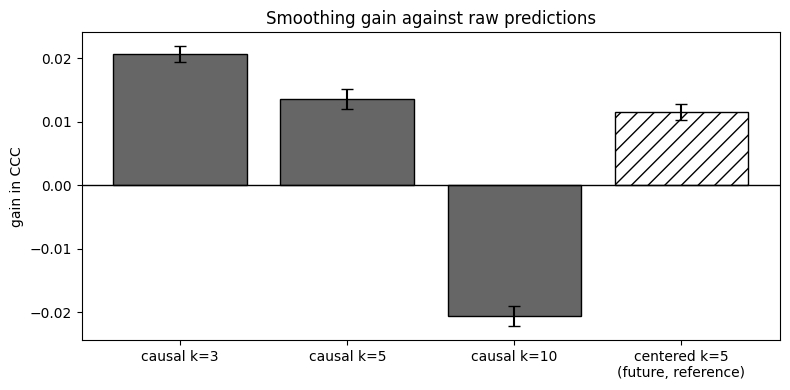

In [5]:
g = sm[sm.smoothing != 'raw']
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(g.smoothing.str.replace(' (uses future, reference only)', '\n(future, reference)'), g.gain_vs_raw, yerr=g.gain_std_over_seeds, color='#666666', edgecolor='black', capsize=4)
for b, f in zip(bars, g.uses_future):
    if f: b.set_hatch('//'); b.set_facecolor('white')
ax.axhline(0, color='black', lw=1); ax.set_ylabel('gain in CCC'); ax.set_title('Smoothing gain against raw predictions'); plt.tight_layout(); plt.show()

**Reading.** Smoothing over 3 or 5 seconds adds a little (+0.02, +0.01), 10 seconds hurts, and the version that uses the future is no better than the past-only version, so smoothing does not leak. The window was inspected on the same folds, so smoothing is not part of the headline result.